In [3]:
from pathlib import Path
import pandas as pd

CSV_PATH = Path("historique_merged.csv")

with CSV_PATH.open("rb") as f:
    nb_lignes = sum(1 for _ in f)
print(f"{nb_lignes:,} lignes dans le fichier".replace(",", " "))

3 757 220 lignes dans le fichier


In [4]:
df = pd.read_csv(CSV_PATH, header=None)
print(df.shape)
df.head()

(3757220, 8)


,0,1,2,3,4,5,6,7
0,2026-10-16T11:52Z,10003,17,1,1,Hauteville - Bonne Nouvelle,"48.87077,2.34965",True
1,2026-10-16T11:52Z,10004,48,1,4,Metz - Faubourg Saint-Denis,"48.87089,2.35352",True
2,2026-10-16T11:52Z,10005,17,0,9,Petites Ecuries - Faubourg Poissonnière,"48.87397,2.34839",True
3,2026-10-16T11:52Z,10006,28,3,20,Petites Ecuries - Faubourg Saint-Denis,"48.87287,2.35422",True
4,2026-10-16T11:52Z,10008,18,4,2,Cité Riverin - Château d'Eau,"48.87070,2.35874",True


In [5]:
# Renommer les colonnes et convertir les types de données
COLONNES = [
    "horodatage", "station_code", "capacity", "velo_meca", "velo_elec",
    "station_name", "coordonnees", "operative",
]

df = pd.read_csv(CSV_PATH, header=None, names=COLONNES)
df["horodatage"] = pd.to_datetime(df["horodatage"], utc=True)
df[["latitude", "longitude"]] = df["coordonnees"].str.split(",", expand=True).astype(float)
df = df.drop(columns="coordonnees")

In [6]:
# Fusion des colonnes "velo_meca" et #velo_elec" pour créer une nouvelle colonne "available" 
df["available"] = df["velo_meca"] + df["velo_elec"]

In [7]:
# Ecarter les stations en dehors de Paris 
dans_paris = df["latitude"].between(48.815, 48.902) & df["longitude"].between(2.224, 2.470)
df = df[dans_paris].copy()

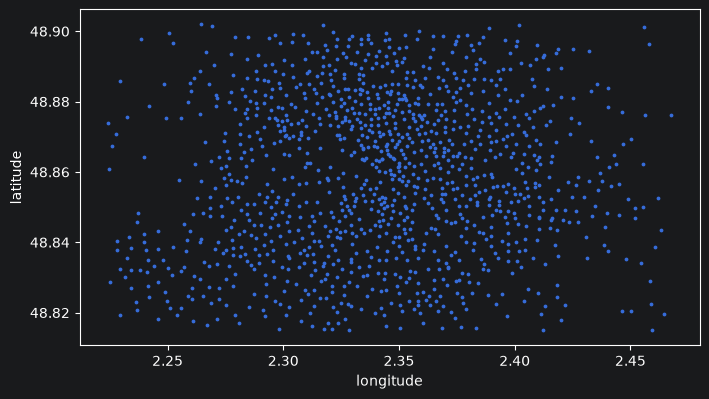

In [8]:
# Voir ce que ça donne sur une carte 
import numpy as np

stations = df.drop_duplicates("station_code")
ax = stations.plot.scatter(x="longitude", y="latitude", s=3, figsize=(8, 8))
ax.set_aspect(1 / np.cos(np.radians(48.86)))

In [9]:
# Suppressions des stations à capacité nulle (0)
df = df[df["capacity"] > 0].copy()

In [10]:
# Vérification 
print(df["capacity"].min()) 
print((df["capacity"] == 0).sum())

11
0


In [11]:
# Je vais chercher à isoler les cas problématiques, c-à-d les stations où la capacité est inférieur aux nombres de vélos dispo
anomalies = df[df["available"] > df["capacity"]].copy()
anomalies["exces"] = anomalies["available"] - anomalies["capacity"]

print(f"{len(anomalies):,} lignes sur {len(df):,} ({len(anomalies) / len(df):.2%})")
print(f"{anomalies['station_code'].nunique()} stations sur {df['station_code'].nunique()}")
anomalies["exces"].describe()

7,463 lignes sur 3,004,147 (0.25%)
17 stations sur 1215


count    7463.000000
mean        9.544687
std         8.191153
min         1.000000
25%         3.000000
50%         7.000000
75%        14.000000
max        40.000000
Name: exces, dtype: float64

In [12]:
# Trouver les cas les plus extrêmes 
anomalies.sort_values("exces", ascending=False).head(10)[
    ["horodatage", "station_code", "station_name", "capacity", "velo_meca", "velo_elec", "operative", "exces"]
]

,horodatage,station_code,station_name,capacity,velo_meca,velo_elec,operative,exces
3250133,2026-10-24 14:25:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,46,36,True,40
3247095,2026-10-24 14:15:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,46,36,True,40
3259247,2026-10-24 14:55:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,45,37,True,40
3257728,2026-10-24 14:50:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,45,37,True,40
3256209,2026-10-24 14:45:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,45,37,True,40
3254690,2026-10-24 14:40:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,45,37,True,40
3253171,2026-10-24 14:35:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,45,37,True,40
3251652,2026-10-24 14:30:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,45,37,True,40
3248614,2026-10-24 14:20:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,46,36,True,40
3245576,2026-10-24 14:10:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,46,36,True,40


In [13]:
# 1. Lignes entièrement identiques (toutes les occurrences marquées)
full_dups = df[df.duplicated(keep=False)]

In [14]:
# 2. Doublons sur la clé logique : même station au même instant
key_dups = df[df.duplicated(subset=["horodatage", "station_code"], keep=False)]
key_dups = key_dups.sort_values(["station_code", "horodatage"])

In [15]:
print(f"Lignes identiques : {len(full_dups)}")
print(f"Doublons (timestamp, station_id) : {len(key_dups)}")
print(key_dups)

Lignes identiques : 0
Doublons (timestamp, station_id) : 0
Empty DataFrame
Columns: [horodatage, station_code, capacity, velo_meca, velo_elec, station_name, operative, latitude, longitude, available]
Index: []


In [16]:
# 3. Pour nettoyer en gardant la première occurrence mais pas besoin parce que pas de doublons
df = df.drop_duplicates(subset=["horodatage", "station_code"], keep="first")

In [17]:
# trie selon le code de station et l'heure pour compter la disponibilité il y a 30 min
df = df.sort_values(["station_code", "horodatage"]).reset_index(drop=True)

# On cherche la ligne exactement il y a 30 min
past = df[["station_code", "horodatage", "available"]].copy()
past["horodatage"] = past["horodatage"] + pd.Timedelta(minutes=30)
past = past.rename(columns={"available": "available_last_30"})

df = df.merge(past, on=["station_code", "horodatage"], how="left")
# pour convertir en Int et pas float
df["available_last_30"] = df["available_last_30"].astype("Int64")

,horodatage,station_code,capacity,velo_meca,velo_elec,station_name,operative,latitude,longitude,available,available_last_30
0,2026-10-16 11:52:00+00:00,1001,17,2,9,Quai de l'Horloge - Pont Neuf,True,48.85706,2.34180,11,<NA>
1,2026-10-16 12:12:00+00:00,1001,17,2,9,Quai de l'Horloge - Pont Neuf,True,48.85706,2.34180,11,<NA>
2,2026-10-16 12:21:00+00:00,1001,17,2,8,Quai de l'Horloge - Pont Neuf,True,48.85706,2.34180,10,<NA>
3,2026-10-16 13:20:00+00:00,1001,17,2,5,Quai de l'Horloge - Pont Neuf,True,48.85706,2.34180,7,<NA>
4,2026-10-16 13:25:00+00:00,1001,17,2,5,Quai de l'Horloge - Pont Neuf,True,48.85706,2.34180,7,<NA>
...,...,...,...,...,...,...,...,...,...,...,...
3004142,2026-10-25 18:15:00+00:00,60002,409,0,0,Concorde - Place de la Madeleine,False,48.87062,2.32422,0,0
3004143,2026-10-25 18:20:00+00:00,60002,409,0,0,Concorde - Place de la Madeleine,False,48.87062,2.32422,0,0
3004144,2026-10-25 18:25:00+00:00,60002,409,0,0,Concorde - Place de la Madeleine,False,48.87062,2.32422,0,0
3004145,2026-10-25 18:30:00+00:00,60002,409,0,0,Concorde - Place de la Madeleine,False,48.87062,2.32422,0,0


Création d'une variable cible




In [18]:
# trie selon le code de station et l'heure pour compter la disponibilité dans 30 min
df = df.sort_values(["station_code", "horodatage"]).reset_index(drop=True)

In [19]:
# On cherche la ligne exactement 30 min plus tard
future = df[["station_code", "horodatage", "available"]].copy()
future["horodatage"] = future["horodatage"] - pd.Timedelta(minutes=30)
future = future.rename(columns={"available": "available_t30"})

In [20]:
df = df.merge(future, on=["station_code", "horodatage"], how="left")
# pour convertir en Int et pas float
df["available_t30"] = df["available_t30"].astype("Int64")

In [21]:
# Pour répérer les nan pour voir la proportion des données manquantes
n_na = df["available_t30"].isna().sum()
print(f"Avaliabe in 30 minutes is NA : {n_na} / {len(df)} ({n_na / len(df):.1%})")

n_na = df["available_last_30"].isna().sum()
print(f"Avaliabe last 30 minutes is NA : {n_na} / {len(df)} ({n_na / len(df):.1%})")

Avaliabe in 30 minutes is NA : 133647 / 3004147 (4.4%)
Avaliabe last 30 minutes is NA : 133647 / 3004147 (4.4%)


In [22]:
# ecarter des valeurs manquantes après le shift
df = df.dropna(subset=["available_t30", "available_last_30"]).reset_index(drop=True)

In [23]:
# introduire la tendance
df["delta_t30"] = df["available"] - df["available_last_30"]

# Catégorie lisible le stock monte, baisse ou reste stable
df["tendance"] = pd.cut(
    df["delta_t30"],
    bins=[-float("inf"), -1, 0, float("inf")],
    labels=["baisse", "stable", "hausse"],
)

In [24]:
# introduire representation cyclique de heure
heure_dec = df["horodatage"].dt.hour + df["horodatage"].dt.minute / 60

df["heure_sin"] = np.sin(2 * np.pi * heure_dec / 24)
df["heure_cos"] = np.cos(2 * np.pi * heure_dec / 24)

In [25]:
# introduire is weekend
df["is_weekend"] = df["horodatage"].dt.dayofweek >= 5
df

,horodatage,station_code,capacity,velo_meca,velo_elec,station_name,operative,latitude,longitude,available,available_last_30,available_t30,delta_t30,tendance,heure_sin,heure_cos,is_weekend
0,2026-10-16 13:50:00+00:00,1001,17,7,7,Quai de l'Horloge - Pont Neuf,True,48.85706,2.34180,14,7,11,7,hausse,-0.461749,-8.870108e-01,False
1,2026-10-16 13:55:00+00:00,1001,17,7,6,Quai de l'Horloge - Pont Neuf,True,48.85706,2.34180,13,7,11,6,hausse,-0.480989,-8.767268e-01,False
2,2026-10-16 14:05:00+00:00,1001,17,7,6,Quai de l'Horloge - Pont Neuf,True,48.85706,2.34180,13,14,10,-1,baisse,-0.518773,-8.549119e-01,False
3,2026-10-16 14:10:00+00:00,1001,17,7,6,Quai de l'Horloge - Pont Neuf,True,48.85706,2.34180,13,14,13,-1,baisse,-0.537300,-8.433914e-01,False
4,2026-10-16 14:15:00+00:00,1001,17,7,6,Quai de l'Horloge - Pont Neuf,True,48.85706,2.34180,13,14,14,-1,baisse,-0.555570,-8.314696e-01,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2795157,2026-10-25 17:45:00+00:00,60002,409,0,0,Concorde - Place de la Madeleine,False,48.87062,2.32422,0,0,0,0,stable,-0.997859,-6.540313e-02,True
2795158,2026-10-25 17:50:00+00:00,60002,409,0,0,Concorde - Place de la Madeleine,False,48.87062,2.32422,0,0,0,0,stable,-0.999048,-4.361939e-02,True
2795159,2026-10-25 17:55:00+00:00,60002,409,0,0,Concorde - Place de la Madeleine,False,48.87062,2.32422,0,0,0,0,stable,-0.999762,-2.181489e-02,True
2795160,2026-10-25 18:00:00+00:00,60002,409,0,0,Concorde - Place de la Madeleine,False,48.87062,2.32422,0,0,0,0,stable,-1.000000,-1.836970e-16,True


Dynamique Globale







In [26]:
print(df["delta_t30"].describe())
print(df["tendance"].value_counts(normalize=True))

count    2795162.0
mean     -0.004273
std       2.101096
min          -65.0
25%           -1.0
50%            0.0
75%            1.0
max           45.0
Name: delta_t30, dtype: Float64
tendance
stable    0.407434
baisse    0.298162
hausse    0.294404
Name: proportion, dtype: float64


In [27]:
# voir les lignes ou la delta min -65
df[df["delta_t30"] == df["delta_t30"].min()]

,horodatage,station_code,capacity,velo_meca,velo_elec,station_name,operative,latitude,longitude,available,available_last_30,available_t30,delta_t30,tendance,heure_sin,heure_cos,is_weekend
1001365,2026-10-23 20:20:00+00:00,12108,66,0,0,Bercy.,True,48.83997,2.37886,0,65,0,-65,baisse,-0.819152,0.573576,False
1001366,2026-10-23 20:25:00+00:00,12108,66,0,0,Bercy.,True,48.83997,2.37886,0,65,0,-65,baisse,-0.806445,0.591310,False
1001367,2026-10-23 20:30:00+00:00,12108,66,0,0,Bercy.,True,48.83997,2.37886,0,65,0,-65,baisse,-0.793353,0.608761,False


Dynamique par station

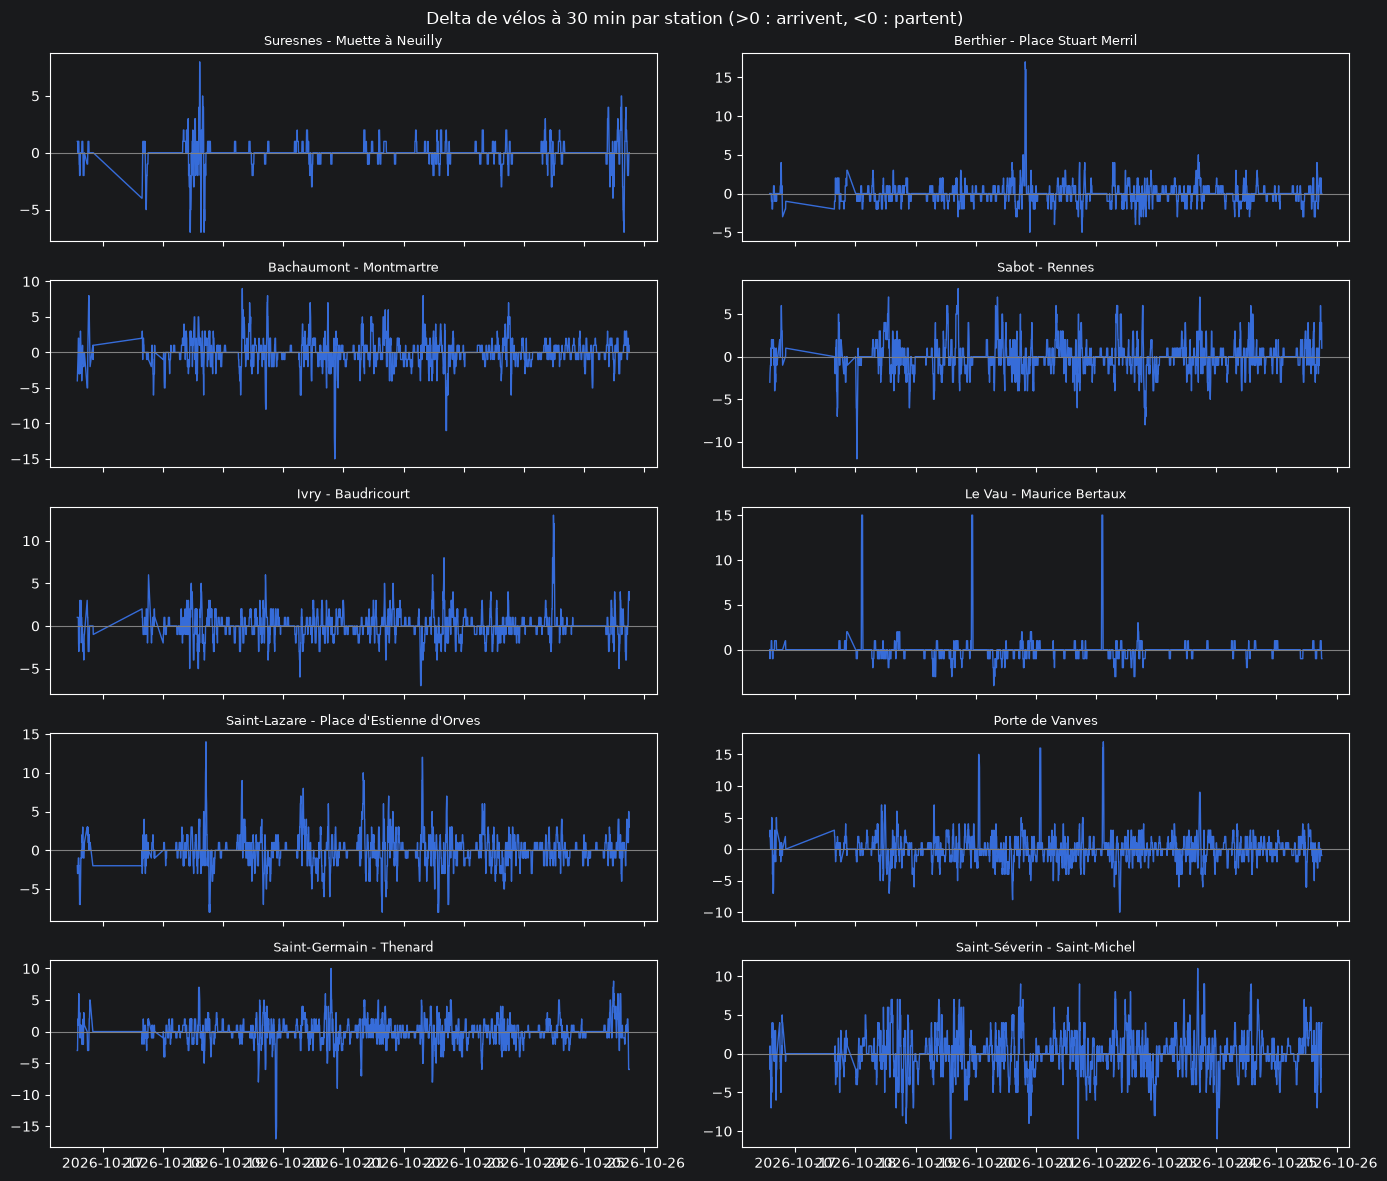

In [28]:
import matplotlib.pyplot as plt

# 10 stations au hasard (random_state fixe pour retrouver les mêmes)
codes = df["station_code"].drop_duplicates().sample(10, random_state=42)

fig, axes = plt.subplots(5, 2, figsize=(14, 12), sharex=True)

for ax, code in zip(axes.flat, codes):
    d = df[df["station_code"] == code].sort_values("horodatage")
    nom = d["station_name"].iloc[0]
    ax.plot(d["horodatage"], d["delta_t30"], linewidth=1)
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_title(nom, fontsize=9)

fig.suptitle("Delta de vélos à 30 min par station (>0 : arrivent, <0 : partent)")
plt.tight_layout()
plt.show()

Dynamique par l'heure


<Axes: title={'center': 'Delta moyen à 30 min par heure (Paris)'}, xlabel='heure'>

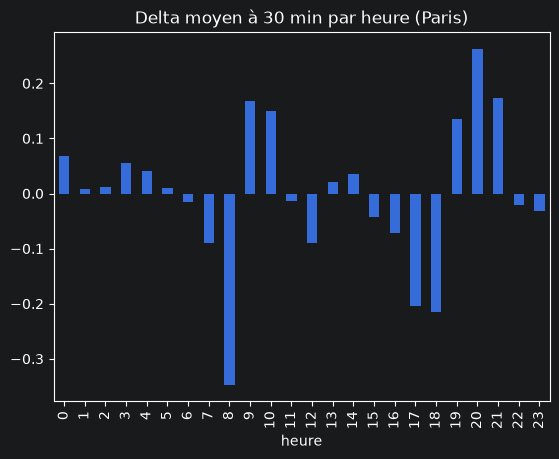

In [29]:
# introduction d'une colonne heure qui signifie l'heure de Paris pour les statistiques en bonne timezone
df["heure"] = df["horodatage"].dt.tz_convert("Europe/Paris").dt.hour
profil_horaire = df.groupby("heure")["delta_t30"].mean()
profil_horaire.plot(kind="bar", title="Delta moyen à 30 min par heure (Paris)")

Les rush hours


En semaine

Rush hours (semaine) : [8, 9, 17, 18, 19, 20]


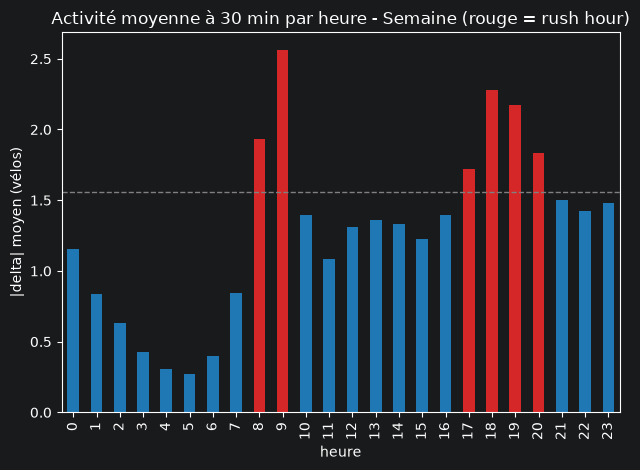

In [30]:
# valeur absolue de delta
df["delta_abs"] = df["delta_t30"].abs()
semaine = df[~df["is_weekend"]]

# Activité moyenne par heure
activite = semaine.groupby("heure")["delta_abs"].mean()

# Rush hour = heures dans les 25 % les plus actives
seuil = activite.quantile(0.75)
rush_hours = activite[activite >= seuil].index.tolist()
print("Rush hours (semaine) :", rush_hours)

# Graphique : rush hours en rouge
couleurs = ["tab:red" if h in rush_hours else "tab:blue" for h in activite.index]
ax = activite.plot(kind="bar", color=couleurs,
                   title="Activité moyenne à 30 min par heure - Semaine (rouge = rush hour)")
ax.axhline(seuil, color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("|delta| moyen (vélos)")
plt.tight_layout()
plt.show()

En weekend

Rush hours (week-end) : [13, 14, 15, 17, 18, 19]


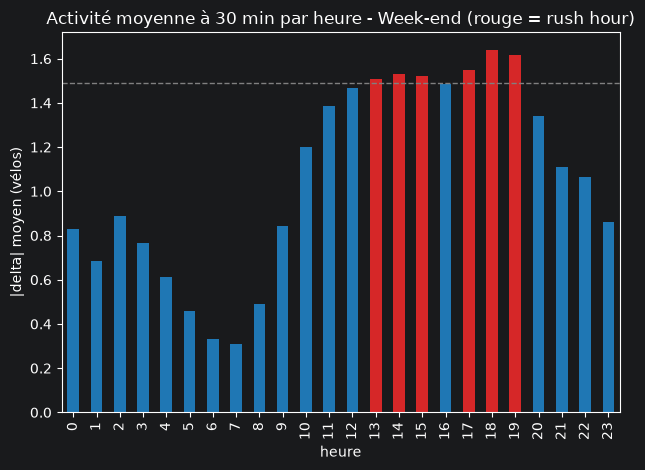

In [31]:
weekend = df[df["is_weekend"]]

# Activité moyenne par heure
activite = weekend.groupby("heure")["delta_abs"].mean()

# Rush hour = heures dans les 25 % les plus actives
seuil = activite.quantile(0.75)
rush_hours = activite[activite >= seuil].index.tolist()
weekend_rush_hours = rush_hours
print("Rush hours (week-end) :", weekend_rush_hours)

# Graphique : rush hours en rouge
couleurs = ["tab:red" if h in rush_hours else "tab:blue" for h in activite.index]
ax = activite.plot(kind="bar", color=couleurs,
                   title="Activité moyenne à 30 min par heure - Week-end (rouge = rush hour)")
ax.axhline(seuil, color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("|delta| moyen (vélos)")
plt.tight_layout()
plt.show()

Rush hours : [9, 16, 17, 18, 19, 20]


Text(0, 0.5, '|delta| moyen (vélos)')

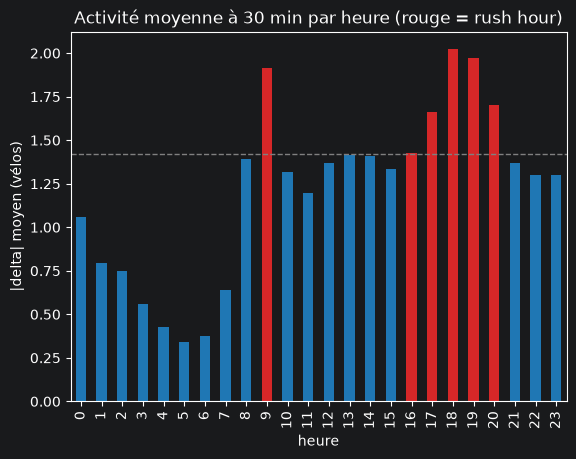

In [32]:
# Activité moyenne par heure
activite = df.groupby("heure")["delta_abs"].mean()

# Rush hour = heures dans les 25 % les plus actives
seuil = activite.quantile(0.75)
rush_hours = activite[activite >= seuil].index.tolist()
week_rush_hours = rush_hours
print("Rush hours :", week_rush_hours)

# Graphique : rush hours en rouge
couleurs = ["tab:red" if h in rush_hours else "tab:blue" for h in activite.index]
ax = activite.plot(kind="bar", color=couleurs,
                   title="Activité moyenne à 30 min par heure (rouge = rush hour)")
ax.axhline(seuil, color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("|delta| moyen (vélos)")

In [33]:
# introduction de rush hour chaque ligne
df["is_rush_hour"] = (
    (df["is_weekend"] & df["heure"].isin(weekend_rush_hours))
    | (~df["is_weekend"] & df["heure"].isin(week_rush_hours))
)

Les données météo

In [34]:
METEO_CSV_PATH = Path("meteo_paris_octobre_2026.csv")

with METEO_CSV_PATH.open("rb") as f:
    nb_lignes = sum(1 for _ in f)
print(f"{nb_lignes:,} lignes dans le fichier".replace(",", " "))

961 lignes dans le fichier


In [35]:
meteo = pd.read_csv(METEO_CSV_PATH)
print(meteo.shape)
meteo.head()

(960, 8)


,date,temperature_2m,apparent_temperature,precipitation,weather_code,wind_speed_10m,rain,weather_label
0,2026-10-16 00:00:00+00:00,16.319500,16.440550,0.0,0.0,5.815978,0.0,Clear sky
1,2026-10-16 00:15:00+00:00,16.269500,16.389246,0.0,1.0,6.151683,0.0,Mainly clear
2,2026-10-16 00:30:00+00:00,16.219501,16.339570,0.0,1.0,6.034700,0.0,Mainly clear
3,2026-10-16 00:45:00+00:00,16.219501,16.339570,0.0,1.0,6.034700,0.0,Mainly clear
4,2026-10-16 01:00:00+00:00,16.169500,16.272877,0.0,1.0,6.034700,0.0,Mainly clear


In [36]:
meteo = meteo.rename(columns={"date": "horodatage"})
meteo["horodatage"] = pd.to_datetime(meteo["horodatage"], utc=True)
meteo.columns.tolist()

['horodatage',
 'temperature_2m',
 'apparent_temperature',
 'precipitation',
 'weather_code',
 'wind_speed_10m',
 'rain',
 'weather_label']

In [37]:
cols_continues = ["temperature_2m", "wind_speed_10m"]
cols_cumul = ["precipitation", "rain"]
cols_label = ["weather_label"]
cols_meteo = cols_continues + cols_cumul + cols_label

m = (meteo.drop_duplicates("horodatage")
       .sort_values("horodatage")
       .set_index("horodatage"))

# L'index porte le nom horodatage
heure_cibles = pd.DatetimeIndex(df["horodatage"].unique(), name="horodatage").sort_values()
index_union = m.index.union(heure_cibles)
base = pd.DataFrame({"horodatage": heure_cibles})

# on interpole des colonnes avec valeur lineeaires
interp = (m[cols_continues].reindex(index_union)
          .interpolate(method="time", limit_area="inside")
          .reindex(heure_cibles))

# pluie et precipitations ce sont des données accumulées delta de 15 min
cumul = pd.merge_asof(
    base, m[cols_cumul].reset_index(),
    on="horodatage", direction="backward", tolerance=pd.Timedelta(minutes=15),
).set_index("horodatage")

# etiquettes le plus proche de 8 mins
label = pd.merge_asof(
    base, m[cols_label].reset_index(),
    on="horodatage", direction="nearest", tolerance=pd.Timedelta(minutes=8),
).set_index("horodatage")

meteo_aligned = pd.concat([interp, cumul, label], axis=1)
meteo_aligned.index.name = "horodatage"          # sécurité
df = df.merge(meteo_aligned.reset_index(), on="horodatage", how="left")

In [38]:
print(df[cols_meteo].isna().mean()) # si 0 partout c'est bien
echantillon = df.sample(100, random_state=42).sort_values("horodatage")
echantillon

temperature_2m    0.0
wind_speed_10m    0.0
precipitation     0.0
rain              0.0
weather_label     0.0
dtype: float64


,horodatage,station_code,capacity,velo_meca,velo_elec,station_name,operative,latitude,longitude,available,...,heure_cos,is_weekend,heure,delta_abs,is_rush_hour,temperature_2m,wind_speed_10m,precipitation,rain,weather_label
2341782,2026-10-18 01:00:00+00:00,21023,25,6,5,Ancienne Mairie - André Morizet,True,48.83831,2.23408,11,...,0.965926,True,3,0,False,8.619500,9.387650,0.0,0.0,Partly cloudy
2150719,2026-10-18 01:15:00+00:00,20004,17,3,1,Commandant l'Herminier - Gallieni,True,48.84704,2.41605,4,...,0.946930,True,3,0,False,8.519500,9.064569,0.0,0.0,Mainly clear
2567406,2026-10-18 03:20:00+00:00,28005,28,8,6,Jean Jaurès - Paul Lafargue,True,48.88493,2.24845,14,...,0.642788,True,5,0,False,7.402833,7.604477,0.0,0.0,Mainly clear
1660431,2026-10-18 04:25:00+00:00,16104,23,8,1,Paul Valery - Victor Hugo,True,48.87137,2.28871,9,...,0.402747,True,6,0,False,7.186167,6.660410,0.0,0.0,Clear sky
1575262,2026-10-18 04:50:00+00:00,16006,19,1,1,Lauriston - Copernic,True,48.86926,2.28992,2,...,0.300706,True,6,0,False,7.102833,6.262843,0.0,0.0,Clear sky
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
863739,2026-10-25 14:25:00+00:00,11039,36,16,3,Richard Lenoir - Jean-Pierre Timbaud,False,48.86580,2.36934,19,...,-0.806445,True,15,2,True,15.469500,22.731428,0.0,0.0,Mainly clear
1727010,2026-10-25 16:10:00+00:00,17010,54,1,5,Jonquière - Docteur Paul Brousse,True,48.89480,2.31871,6,...,-0.461749,True,17,1,True,14.286166,21.231787,0.0,0.0,Mainly clear
2424521,2026-10-25 16:35:00+00:00,21313,26,24,1,Guynemer - Séverine,True,48.83092,2.27907,25,...,-0.362438,True,17,0,True,13.952833,17.865245,0.0,0.0,Mainly clear
13803,2026-10-25 17:25:00+00:00,1008,32,4,4,Les Halles - Saint-Eustache,False,48.86363,2.34262,8,...,-0.152123,True,18,0,True,13.319500,13.325488,0.0,0.0,Partly cloudy


In [39]:
# derniere normalisation des valeurs de meteo
cols_num = ["temperature_2m", "wind_speed_10m", "precipitation", "rain"]
df[cols_num] = df[cols_num].apply(pd.to_numeric, errors="coerce").astype("float64").round(2)

## Export du dataset nettoyé

In [40]:
SORTIE = Path("raw/data/historique_nettoye.csv")
SORTIE.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(SORTIE, index=False)